In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
%matplotlib inline

In [21]:
import scipy.odr as odr

from glob import glob

#

# Calibrations

## Task 6.2.2 [2 absorbers with different temperatures]

In [3]:
def func_straight_line(x, m, c):
    """
    """
    return m*np.asarray(x) + c # = y


### 2nd attempt values

In [4]:
T_absorber_hot = 22.5 + 273.15 # convert Celsius to Kelvin
errT_absorber_hot = 0.5 # convert Celsius to Kelvin
T_absorber_cold = 1.5 + 273.15 # convert Celsius to Kelvin
errT_absorber_cold = 0.5 # convert Celsius to Kelvin

P_cold_task622 = 42_006
errP_cold_task622 = 186
P_hot_task622 = 42_783
errP_hot_task622 = 105


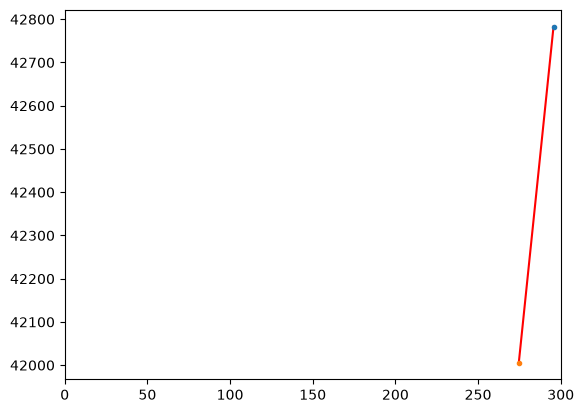

In [5]:
plt.plot(np.array([T_absorber_cold, T_absorber_hot]), np.array([P_cold_task622, P_hot_task622]), 'r-')

plt.plot(T_absorber_hot, P_hot_task622, '.')
plt.plot(T_absorber_cold, P_cold_task622, '.')

#plt.ylim(0, 43_000)
plt.xlim(0, 300);


$P_{absorber} = \alpha_{max}(T_{absober} + T_{sys}) = \alpha_{max}T_{absorber} + (\alpha_{max}T_{sys})$    
$y = mx + c$     
=> $m=\alpha_{max} = \frac{y_2-y_1}{x_2-x_1} = \frac{P_{absorber,hot}-P_{absorber,cold}}{T_{absorber,hot}-T_{absorber,cold}}$

In [6]:
print( (P_hot_task622-P_cold_task622)/(T_absorber_cold-T_absorber_hot) )

-37.0


$c = (\alpha_{max}T_{sys})$ => $T_{sys} = \frac{c}{\alpha_{max}} = \frac{c}{m}$

In [7]:
pars_task622, cov_task622 = curve_fit(func_straight_line, xdata=np.array([T_absorber_cold, T_absorber_hot]), ydata=np.array([P_cold_task622, P_hot_task622])) 
            # will have to give uncertainties
# popt, pcov = curve_fit(function, xdata, ydata, sigma=yerr, absolute_sigma=True, p0=initial_pars)

#pars contains the fitted parameters
# => for fitfunc used here, pars[0] = m (slope) & pars[1] = c (intercept)
#cov = the covariance matrix & can be used to get the error on the slope & intercept
# => for fitfunc used here, np.sqrt(cov[0,0]) = err_slope & np.sqrt(cov[1,1]) = err_intercept
print(pars_task622[0], pars_task622[1])

36.99999999999996 31843.95000000001


C:\Users\cathe\AppData\Local\Temp\ipykernel_19040\4071669496.py:1: OptimizeWarning: Covariance of the parameters could not be estimated
  pars_task622, cov_task622 = curve_fit(func_straight_line, xdata=np.array([T_absorber_cold, T_absorber_hot]), ydata=np.array([P_cold_task622, P_hot_task622]))


In [8]:
print(pars_task622[1]/pars_task622[0]) # T_sys = c/m


860.6472972972986


### Final attempt values

In [9]:
# arranged in order of temp. : final_cold, earlier_cold, earlier_hot, final_hot (was final[hot,cold], earlier[hot,cold])
task622_full_Tabs_array = 273.15+ np.array([-3.5, 2.0, 22.0, 28.0])# 28.0, -3.5, 22.0, 2.0]) 
task622_full_P_array = np.array([43_435, 42_006, 42_783, 45_868])# 45_868, 43_435, 42_783, 42_006])
task622_full_errT_array = np.array([0.5, 1.5, 1.5, 0.5])
task622_full_errP_array = np.array([139, 186, 105, 171])# 171, 139, 105, 186]) 

# first two values are from final attempt, next two are from earlier in observing day 2 [increasing the uncertainty in their temp.]
task622_T_abs_array = 273.15+ np.array([28.0, -3.5])#, 22.5, 1.5])
# to convert from Celsius to Kelvin # in order of: hot, cold
task622_errT_array = np.array([0.5, 0.5])#, 1.5, 1.5]) # hot, cold
# np.array([1.5, 1.5]) # briefly trying larger errors for the Temp. => doesn't help at all really


task622_P_array = np.array([45_868, 43_435])#, 42_783, 42_006]) # hot, cold
task622_errP_array = np.array([171, 139])#, 105, 186]) # hot, cold


In [10]:
### ROUGH LOOK AT WHAT T_SYS COULD BE:
pars_task622, cov_task622 = curve_fit(func_straight_line, task622_T_abs_array, task622_P_array, sigma=task622_errP_array, absolute_sigma=True) 
            # will have to give uncertainties
# popt, pcov = curve_fit(function, xdata, ydata, sigma=yerr, absolute_sigma=True, p0=initial_pars)

#pars contains the fitted parameters
# => for fitfunc used here, pars[0] = m (slope) & pars[1] = c (intercept)
#cov = the covariance matrix & can be used to get the error on the slope & intercept
# => for fitfunc used here, np.sqrt(cov[0,0]) = err_slope & np.sqrt(cov[1,1]) = err_intercept
print(pars_task622[0], pars_task622[1]) # m, c
print(np.sqrt(cov_task622[0,0]), np.sqrt(cov_task622[1,1]))

print('\n', pars_task622[1]/pars_task622[0]) # T_sys = c/m

77.2380952380954 22607.74761904757
6.995805474674811 1977.0395265754942

 292.70203452527625


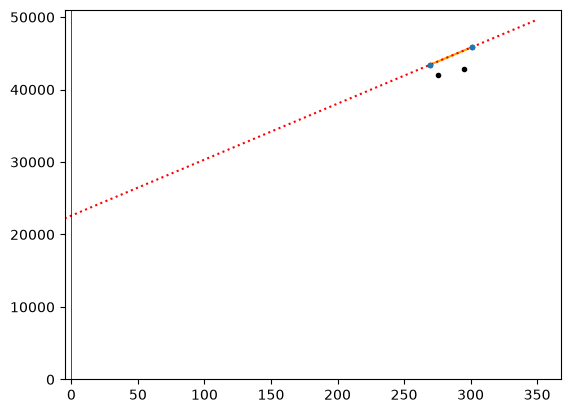

In [11]:
plt.plot(task622_T_abs_array, task622_P_array, color='orange')
plt.errorbar(task622_T_abs_array, task622_P_array, yerr=task622_errP_array, xerr=task622_errT_array, fmt='.', zorder=10);

plt.errorbar(task622_full_Tabs_array, task622_full_P_array, yerr=task622_full_errP_array, xerr=task622_full_errT_array, fmt='.', color='k', zorder=8) # can see where the other values sit in comparison

testX_plotting = np.linspace(-5, 350, 100)
plt.plot(testX_plotting, pars_task622[0]*testX_plotting + pars_task622[1], 'r:') # y=mx+c

plt.ylim(0)
plt.axvline(0, color='k', linewidth=0.5)
plt.xlim(np.min(testX_plotting));

#plt.xlim(250,320)
#plt.ylim(40_000); # error bars = so small in comparison to full plot // have to zoom in to see

In [12]:
# have to fit a line with error bars in *both* directions [error propagation is *not sufficient)

In [13]:
     # trying scipy's ODR
task622_data = odr.RealData(task622_T_abs_array, task622_P_array, sx=task622_errT_array, sy=task622_errP_array) # x, y, err_x, err_y

In [14]:
# 
def func_model_straight_line(p, x):
    m, c = p
    return m * x + c

task622_model = odr.Model(func_model_straight_line) # func_straight_line)#

In [15]:
# p_odr = scipy.odr.ODR(p_dat, p_mod, beta0=[1., 1.])
task622_odr = odr.ODR(task622_data, task622_model, beta0=[pars_task622[0], pars_task622[1]]) # have to give some sort of initial param.s

task622_odr_output = task622_odr.run()
task622_odr_output.pprint() # fitting a straight line to only 2 points, so not really a surprise that m&c parameters = as w/curve_fit

Beta: [   77.23809524 22607.74761905]
Beta Std Error: [1.56384310e-28 4.42241585e-26]
Beta Covariance: [[ 5.19474512e+01 -1.46683428e+04]
 [-1.46683428e+04  4.15429223e+06]]
Residual Variance: 4.707844525982228e-58
Inverse Condition #: 0.027104004940435255
Reason(s) for Halting:
  Parameter convergence


In [16]:
print(task622_odr_output.beta[1]/task622_odr_output.beta[0]) # T_sys = c/m
## still need the final, overall uncertainties [Can we do error propagation here or not???]

# technically sd_beta [Beta Std error] = the uncertainty on the parameters. 
    # It's given by: np.sqrt(np.diag(output.cov_beta * output.res_var))
    # & the residual variance = 
print(np.sqrt(task622_odr_output.cov_beta))
# while the results from sqrt(beta_cov) look far more reasonable, apparently these aren't the actual uncertainties...

292.70203452527795
[[   7.20745802           nan]
 [          nan 2038.20809255]]


C:\Users\cathe\AppData\Local\Temp\ipykernel_19040\1975487454.py:7: RuntimeWarning: invalid value encountered in sqrt
  print(np.sqrt(task622_odr_output.cov_beta))


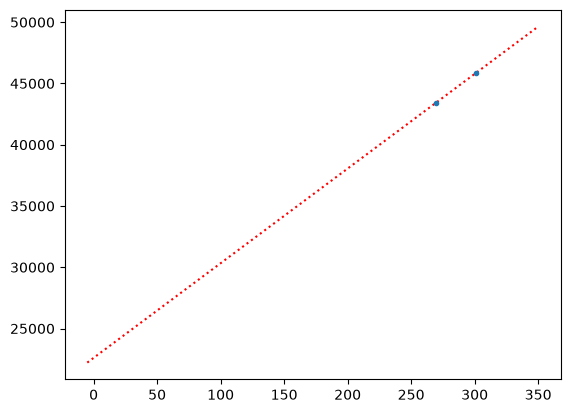

In [17]:
plt.errorbar(task622_T_abs_array, task622_P_array, yerr=task622_errP_array, xerr=task622_errT_array, fmt='.', zorder=10);
plt.plot(testX_plotting, testX_plotting*task622_odr_output.beta[0] + task622_odr_output.beta[1], 'r:');

#### Looking into results if derive uncertainty on m & c from error propagation
$m = \frac{y_2 - y_1}{x_2 - x_1}$   
$\to \Delta m = \frac{1}{x_2 - x_1}\sqrt{(y_1 \Delta y_2)^2 + (y_2 \Delta y_1)^2 + 2(\frac{m\Delta x}{x_2-x_1})^2}$    

$c = y - mx \equiv y_1 - mx_1 $    
$\to \Delta c = \sqrt{\Delta y^2 + (x\Delta m)^2 + (m\Delta x)^2}$

In [18]:
#task622_T_abs_array, task622_errT_array # done in order of hot [x_2], then cold [x_1]
#task622_P_array, task622_errP_array
test_task622_m = (task622_P_array[0] - task622_P_array[1])/(task622_T_abs_array[0] - task622_T_abs_array[1])
print('m: ', test_task622_m)
print('c: ', task622_P_array - test_task622_m*task622_T_abs_array)

test_task622_errM = np.sqrt((task622_P_array[1]*task622_errP_array[0])**2 + (task622_P_array[0]*task622_errP_array[1])**2 + 2*(test_task622_m*task622_errT_array[0]/(task622_T_abs_array[0] - task622_T_abs_array[1]))**2)/(task622_T_abs_array[0] - task622_T_abs_array[1])
print('err_m: ', test_task622_errM)
print('err_c: ', np.sqrt((task622_errP_array)**2 + (test_task622_errM*task622_T_abs_array)**2 + (test_task622_m*task622_errT_array)**2))
# uncertainties derived for m & c are far too large [in comparison to m & c themselves], so disregard this method

m:  77.23809523809524
c:  [22607.74761905 22607.74761905]
err_m:  310746.4438155294
err_c:  [93581291.55521087 83792778.57498169]


#### Next, try adding in more data points [see above] [all values from Observing Day 2]

In [19]:
task622_full_data = odr.RealData(task622_full_Tabs_array, task622_full_P_array, sx=task622_full_errT_array, sy=task622_full_errP_array)
task622_odr_full = odr.ODR(task622_full_data, task622_model, beta0=[pars_task622[0], pars_task622[1]]) # have to give some sort of initial param.s
task622_odr_full_output = task622_odr_full.run()
task622_odr_full_output.pprint()
print(task622_odr_full_output.beta[1]/task622_odr_full_output.beta[0]) # T_sys = c/m

Beta: [   88.3745667  18481.99491731]
Beta Std Error: [   70.66463964 19916.15011348]
Beta Covariance: [[ 4.95549732e+01 -1.39532684e+04]
 [-1.39532684e+04  3.93635021e+06]]
Residual Variance: 100.76670363324614
Inverse Condition #: 0.021794638162557358
Reason(s) for Halting:
  Sum of squares convergence
209.13250957395553


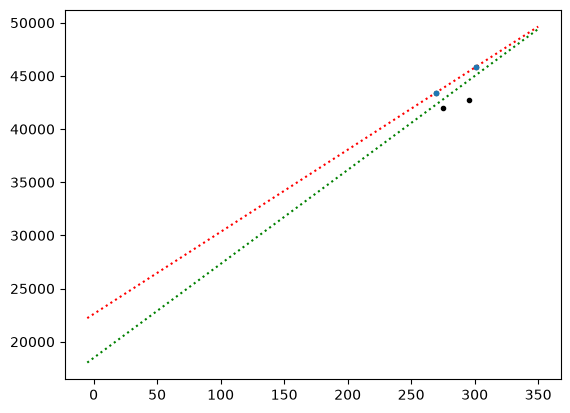

In [20]:
plt.errorbar(task622_T_abs_array, task622_P_array, yerr=task622_errP_array, xerr=task622_errT_array, fmt='.', zorder=10);
plt.plot(testX_plotting, testX_plotting*task622_odr_output.beta[0] + task622_odr_output.beta[1], 'r:');

plt.errorbar(task622_full_Tabs_array, task622_full_P_array, yerr=task622_full_errP_array, xerr=task622_full_errT_array, fmt='.', color='k',zorder=8);
plt.plot(testX_plotting, testX_plotting*task622_odr_full_output.beta[0] + task622_odr_full_output.beta[1], 'g:');



### Looking into importing Data files/using the .py files given

In [28]:
filepath = 'Data/261123/'
day2_data_filepaths = glob(filepath+'261124_*.tab')
print(day2_data_filepaths) 
day2_finalAbsorber_filepaths = glob(filepath+'261124_*absorber*newtest2.tab') 
# interested in absorber files [I think...] => final measurements = newtest2
print(day2_finalAbsorber_filepaths)

['Data/261123\\261124_114614_Sun_long_sun_exposure_behind.tab', 'Data/261123\\261124_120923_Cold_261124_2_Cold_261124_2_test.tab', 'Data/261123\\261124_130122_Cold_261124_1_Cold_251124_1.tab', 'Data/261123\\261124_130526_Cold_261124_2_cold_261124_2_test2.tab', 'Data/261123\\261124_130933_G20_behindtrees1.tab', 'Data/261123\\261124_131640_G30_behindtrees1.tab', 'Data/261123\\261124_132813__warm_absorber_black_newt.tab', 'Data/261123\\261124_134036__cold_absorber_black_newt.tab', 'Data/261123\\261124_134434__cold_absorber_black_newt.tab', 'Data/261123\\261124_134649_G40_G40.tab', 'Data/261123\\261124_135825_G50_G50.tab', 'Data/261123\\261124_141928_G60_G60.tab', 'Data/261123\\261124_144408_G70_G70.tab', 'Data/261123\\261124_144408_G70_G70_part.tab', 'Data/261123\\261124_145751_G80_G80.tab', 'Data/261123\\261124_145751_G80_G80_part.tab', 'Data/261123\\261124_151249__.tab', 'Data/261123\\261124_151732__mobile_phone_on.tab', 'Data/261123\\261124_151923__mobile_phone_on_notinfee.tab', 'Data/

In [25]:
# py files sent in email = npoints.py, radio_flat.py, radio_header.py, radio_simple.py, radio_spectra.py
# put all py files in main folder/move up & out of data subfolder

py_filepaths = glob('*.py')
print(py_filepaths) 

['npoints.py', 'radio_flat.py', 'radio_header.py', 'radio_spectra.py']


In [29]:
import radio_spectra

SyntaxError: Missing parentheses in call to 'print'. Did you mean print(...)? (radio_spectra.py, line 60)

In [31]:
# part of task = to plot spectra calibrated with factor 1/alpha_max = 1/m
    # alpha_max = slope m = 
print(task622_odr_output.beta[0], 1/task622_odr_output.beta[0])
print(task622_odr_full_output.beta[0], 1/task622_odr_full_output.beta[0]) # all data from observing day 2

77.23809523809517 0.012946979038224426
88.37456670393873 0.01131547273493372


In [33]:
# not sure what's the max precision that I can set factor=1/alpha_max to when changing it for the spectra
    # likely better to get uncertainty on 1/alpha 1st, & try and give it to that uncertainty
# but for moment

# currently [before any changes] factor = 1.28000e-02 for both warm&cold absorber [newtest2//final measurements]
print(1.28000e-02) # so should be able to give result to fairly good precision => again, stick to precision given by uncertainty
    # the value originally given has 6 figures in it [that's its precision]
print(f'{1/task622_odr_output.beta[0]:.6g}')
print(f'{1/task622_odr_full_output.beta[0]:.6g}')

0.0128
0.012947
0.0113155
